<a href="https://colab.research.google.com/github/kn25aan/Msc-final-project-24108445/blob/main/tb_xray_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

GPU available: True
Tesla T4


In [ ]:
!wget https://data.lhncbc.nlm.nih.gov/public/Tuberculosis-Chest-X-ray-Datasets/Montgomery-County-CXR-Set/MontgomerySet/CXR_png/MCUCXR_0001_0.png -P /content/test
!ls -lh /content/test

--2026-10-23 08:39:25--  https://data.lhncbc.nlm.nih.gov/public/Tuberculosis-Chest-X-ray-Datasets/Montgomery-County-CXR-Set/MontgomerySet/CXR_png/MCUCXR_0001_0.png
Resolving data.lhncbc.nlm.nih.gov (data.lhncbc.nlm.nih.gov)... 99.86.101.69, 99.86.101.114, 99.86.101.21, ...
Connecting to data.lhncbc.nlm.nih.gov (data.lhncbc.nlm.nih.gov)|99.86.101.69|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 5202442 (5.0M) [image/png]
Saving to: ‘/content/test/MCUCXR_0001_0.png’

MCUCXR_0001_0.png   100%[===================>]   4.96M  --.-KB/s    in 0.06s   

2026-10-23 08:39:25 (84.4 MB/s) - ‘/content/test/MCUCXR_0001_0.png’ saved [5202442/5202442]

total 5.0M
-rw-r--r-- 1 root root 5.0M Aug 28  2024 MCUCXR_0001_0.png


## Getting the file list and download Montgomery

In [ ]:
import os, re, requests
from tqdm import tqdm

base = "https://data.lhncbc.nlm.nih.gov/public/Tuberculosis-Chest-X-ray-Datasets/Montgomery-County-CXR-Set/MontgomerySet/CXR_png/"

r = requests.get(base + "index.html")
print("page status:", r.status_code, "| page length:", len(r.text))

names = sorted(set(re.findall(r"[A-Za-z0-9_\-]+\.png", r.text)))
print("png files found in the listing:", len(names), names[:3])

if names:
    os.makedirs("/content/montgomery", exist_ok=True)
    for n in tqdm(names):
        out = "/content/montgomery/" + n
        if not os.path.exists(out):
            with open(out, "wb") as f:
                f.write(requests.get(base + n).content)
    print("files on disk:", len(os.listdir("/content/montgomery")))
else:
    print(r.text[:500])

page status: 200 | page length: 23032
png files found in the listing: 138 ['MCUCXR_0001_0.png', 'MCUCXR_0002_0.png', 'MCUCXR_0003_0.png']


100%|██████████| 138/138 [01:31<00:00,  1.50it/s]

files on disk: 138


Download the Shenzhen images

In [ ]:
base = "https://data.lhncbc.nlm.nih.gov/public/Tuberculosis-Chest-X-ray-Datasets/Shenzhen-Hospital-CXR-Set/CXR_png/"

r = requests.get(base + "index.html")
print("page status:", r.status_code, "| page length:", len(r.text))

names = sorted(set(re.findall(r"[A-Za-z0-9_\-]+\.png", r.text)))
print("png files found in the listing:", len(names), names[:3])

if names:
    os.makedirs("/content/shenzhen", exist_ok=True)
    for n in tqdm(names):
        out = "/content/shenzhen/" + n
        if not os.path.exists(out):
            with open(out, "wb") as f:
                f.write(requests.get(base + n).content)
    print("files on disk:", len(os.listdir("/content/shenzhen")))
else:
    print(r.text[:500])

page status: 200 | page length: 106842
png files found in the listing: 662 ['CHNCXR_0001_0.png', 'CHNCXR_0002_0.png', 'CHNCXR_0003_0.png']


100%|██████████| 662/662 [04:01<00:00,  2.74it/s]

files on disk: 662


## Building the table of images and labels

In [ ]:
import pandas as pd

rows = []
for country in ["montgomery", "shenzhen"]:
    folder = "/content/" + country
    for f in sorted(os.listdir(folder)):
        if f.endswith(".png"):
            label = int(f[-5])        # the digit just before ".png": 0 = normal, 1 = TB
            rows.append({"country": country, "path": folder + "/" + f, "label": label})

df = pd.DataFrame(rows)
print(df.shape)
print(df.groupby(["country", "label"]).size())
df.head(3)

(800, 3)
country     label
montgomery  0         80
            1         58
shenzhen    0        326
            1        336
dtype: int64


,country,path,label
0,montgomery,/content/montgomery/MCUCXR_0001_0.png,0
1,montgomery,/content/montgomery/MCUCXR_0002_0.png,0
2,montgomery,/content/montgomery/MCUCXR_0003_0.png,0


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## visuliasing random sapmles of two countires data

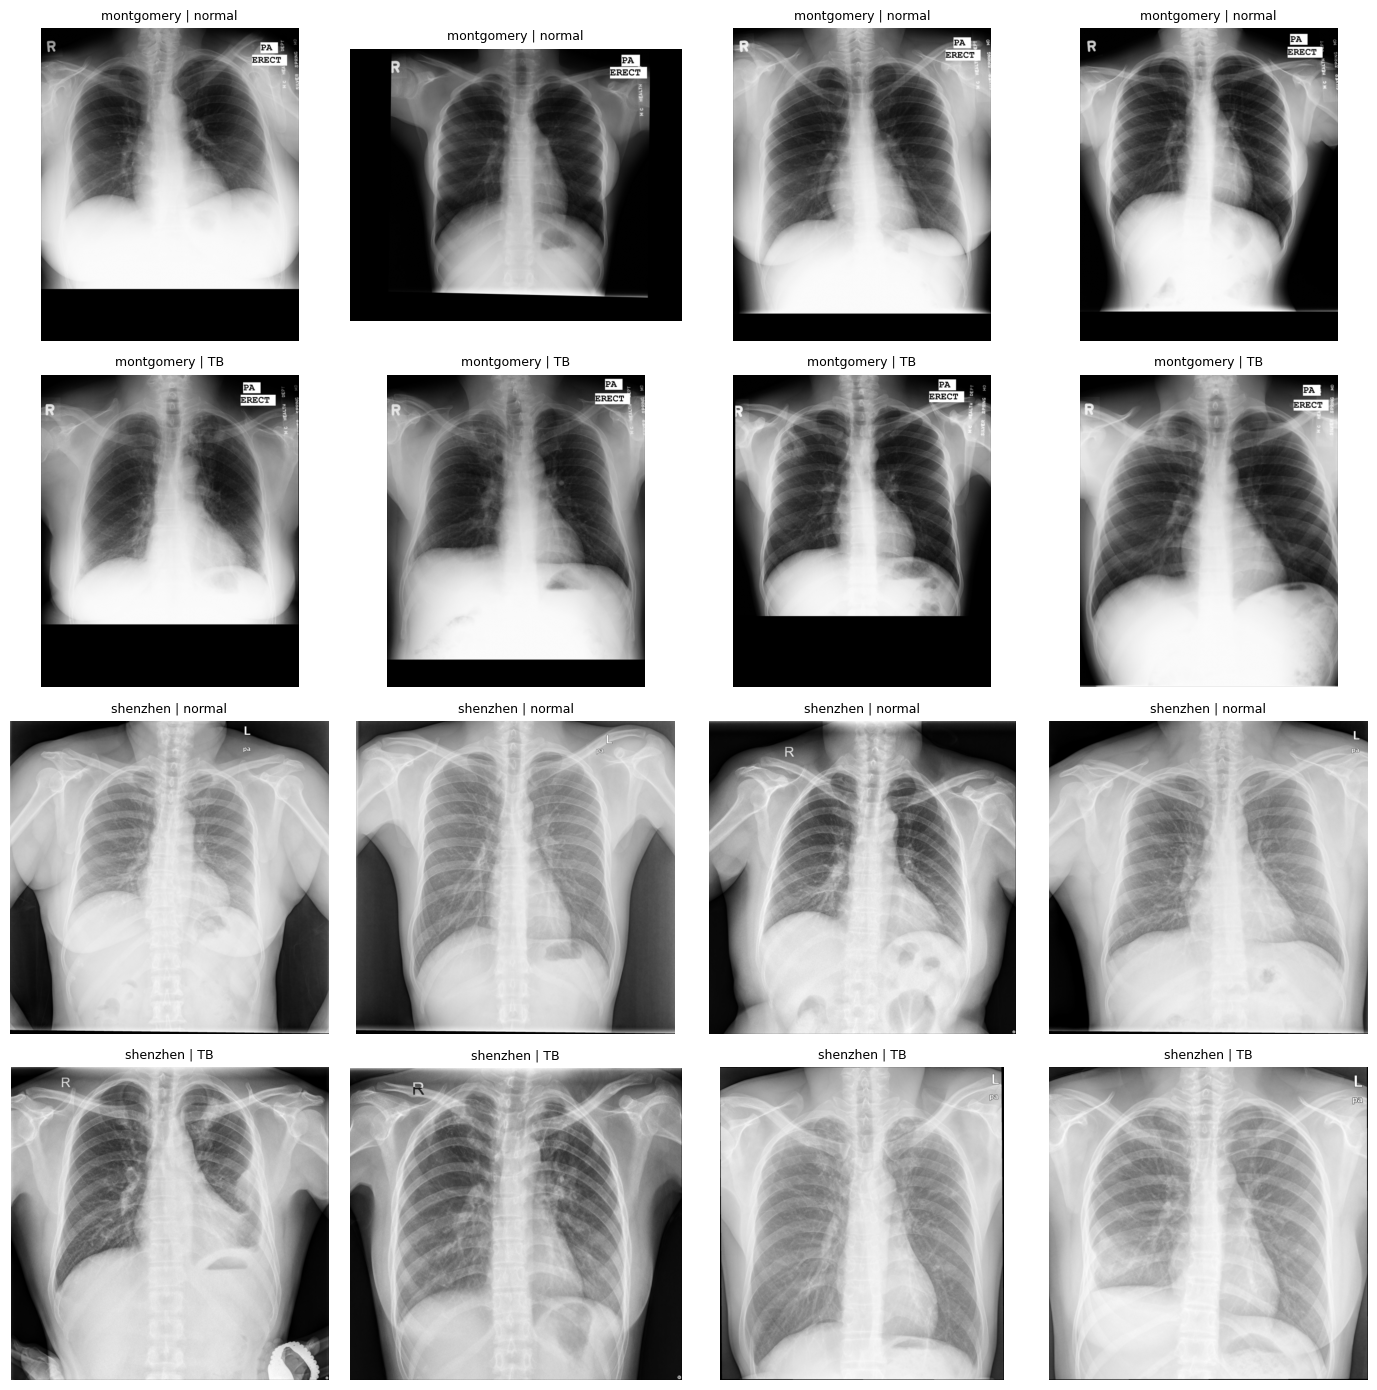

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

combos = [("montgomery", 0), ("montgomery", 1), ("shenzhen", 0), ("shenzhen", 1)]
fig, axes = plt.subplots(4, 4, figsize=(14, 14))

for r, (country, label) in enumerate(combos):
    sub = df[(df.country == country) & (df.label == label)].sample(4, random_state=0)
    for c, (_, row) in enumerate(sub.iterrows()):
        img = Image.open(row.path).convert("L")
        img.thumbnail((600, 600))
        axes[r, c].imshow(img, cmap="gray")
        axes[r, c].set_title(f"{country} | {'TB' if label else 'normal'}", fontsize=9)
        axes[r, c].axis("off")

plt.tight_layout()
plt.show()

Connect your Google Drive

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
os.makedirs("/content/drive/MyDrive/tb_xray", exist_ok=True)
print("Folder contents:", os.listdir("/content/drive/MyDrive/tb_xray"))

Mounted at /content/drive
Folder contents: ['cache_224.npz', 'labels.csv', 'all_results.csv']


Resize all 800 images and save them to Drive

In [ ]:
import numpy as np
from tqdm import tqdm
from PIL import Image

def squash(path, size=224):
    im = Image.open(path).convert("L")
    return np.array(im.resize((size, size)))

def pad(path, size=224):
    im = Image.open(path).convert("L")
    im.thumbnail((size, size))
    canvas = Image.new("L", (size, size), 0)
    canvas.paste(im, ((size - im.width) // 2, (size - im.height) // 2))
    return np.array(canvas)

X_squash, X_pad = [], []
for p in tqdm(df.path):
    X_squash.append(squash(p))
    X_pad.append(pad(p))

X_squash, X_pad = np.stack(X_squash), np.stack(X_pad)

save_path = "/content/drive/MyDrive/tb_xray/cache_224.npz"
np.savez_compressed(save_path, squash=X_squash, pad=X_pad,
                    label=df.label.values, country=df.country.values)
df.to_csv("/content/drive/MyDrive/tb_xray/labels.csv", index=False)

print(X_squash.shape, X_pad.shape)
print("Saved:", save_path, "|", round(os.path.getsize(save_path) / 1e6, 1), "MB")

100%|██████████| 800/800 [03:23<00:00,  3.94it/s]


(800, 224, 224) (800, 224, 224)
Saved: /content/drive/MyDrive/tb_xray/cache_224.npz | 59.8 MB


The set-up

In [ ]:
import os, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix
from google.colab import drive

drive.mount("/content/drive")
FOLDER = "/content/drive/MyDrive/tb_xray"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

data = np.load(FOLDER + "/cache_224.npz", allow_pickle=True)
X, y, country = data["squash"], data["label"], data["country"]

splits = {}
for c in ["montgomery", "shenzhen"]:
    idx = np.where(country == c)[0]
    tr, te = train_test_split(idx, test_size=0.2, stratify=y[idx], random_state=42)
    splits[c] = (tr, te)
    print(c, "| train:", len(tr), "| test:", len(te), "| TB in test:", y[te].sum())

class XrayDataset(Dataset):
    def __init__(self, X, y, idx):
        self.X, self.y = X[idx], y[idx]
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        img = torch.tensor(self.X[i], dtype=torch.float32) / 255.0
        img = (img - 0.45) / 0.225
        return img.unsqueeze(0).repeat(3, 1, 1), int(self.y[i])

def make_loader(idx, shuffle=False, batch_size=16):
    return DataLoader(XrayDataset(X, y, idx), batch_size=batch_size, shuffle=shuffle)

def new_model(name="resnet50"):
    return timm.create_model(name, pretrained=True, num_classes=2).to(device)

def predict(model, loader):
    model.eval()
    probs, labs_all = [], []
    with torch.no_grad():
        for imgs, labs in loader:
            p = torch.softmax(model(imgs.to(device)), dim=1)[:, 1]
            probs.extend(p.cpu().tolist())
            labs_all.extend(labs.tolist())
    return np.array(probs), np.array(labs_all)

def train(model, loader, epochs, lr=1e-4, print_every=10):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    for ep in range(epochs):
        model.train()
        total = 0
        for imgs, labs in loader:
            imgs, labs = imgs.to(device), labs.to(device)
            opt.zero_grad()
            loss = loss_fn(model(imgs), labs)
            loss.backward()
            opt.step()
            total += loss.item() * len(labs)
        if ep == 0 or (ep + 1) % print_every == 0:
            print(f"  epoch {ep+1}/{epochs} | loss {total/len(loader.dataset):.3f}")

def bootstrap_auc(labels, probs, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    scores = []
    for _ in range(n):
        i = rng.integers(0, len(labels), len(labels))
        if len(np.unique(labels[i])) < 2:
            continue
        scores.append(roc_auc_score(labels[i], probs[i]))
    return np.percentile(scores, [2.5, 97.5])

def row(name, p, l):
    lo, hi = bootstrap_auc(l, p)
    return dict(experiment=name, auc=round(roc_auc_score(l, p), 3),
                ci_low=round(lo, 3), ci_high=round(hi, 3),
                accuracy=round(accuracy_score(l, p > 0.5), 3), n_test=len(l))

def run_experiment(name, lr=1e-4, ep_m=40, ep_s=30, seed=42):
    out = []
    for src, tgt, epochs in [("montgomery", "shenzhen", ep_m), ("shenzhen", "montgomery", ep_s)]:
        print(f"{name}: training on {src}")
        torch.manual_seed(seed)
        m = new_model(name)
        tr_idx, te_idx = splits[src]
        train(m, make_loader(tr_idx, shuffle=True), epochs=epochs, lr=lr)
        p_in, l_in = predict(m, make_loader(te_idx))
        p_x, l_x = predict(m, make_loader(np.where(country == tgt)[0]))
        out.append(row(f"{src.capitalize()}->{src.capitalize()} (held-out)", p_in, l_in))
        out.append(row(f"{src.capitalize()}->{tgt.capitalize()} (all)", p_x, l_x))
        del m
        torch.cuda.empty_cache()
    res = pd.DataFrame(out)
    res["model"] = name
    res["resize"] = "squash"
    return res



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using: cuda
montgomery | train: 110 | test: 28 | TB in test: 12
shenzhen | train: 529 | test: 133 | TB in test: 68


Train and test with ResNet-50

In [ ]:
new = run_experiment("resnet50", lr=1e-4)
print(new.to_string(index=False))

all_results = pd.concat([all_results, new], ignore_index=True)
all_results.to_csv(RESULTS_FILE, index=False)
print("Saved to Drive:", RESULTS_FILE)

resnet50: training on montgomery


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

  epoch 1/40 | loss 0.692
  epoch 10/40 | loss 0.495
  epoch 20/40 | loss 0.199
  epoch 30/40 | loss 0.057
  epoch 40/40 | loss 0.009
resnet50: training on shenzhen
  epoch 1/30 | loss 0.682
  epoch 10/30 | loss 0.088
  epoch 20/30 | loss 0.030
  epoch 30/30 | loss 0.011
                       experiment   auc  ci_low  ci_high  accuracy  n_test    model resize
Montgomery->Montgomery (held-out) 0.828   0.622    1.000     0.857      28 resnet50 squash
       Montgomery->Shenzhen (all) 0.749   0.711    0.785     0.683     662 resnet50 squash
    Shenzhen->Shenzhen (held-out) 0.890   0.821    0.942     0.872     133 resnet50 squash
       Shenzhen->Montgomery (all) 0.686   0.593    0.775     0.587     138 resnet50 squash
Saved to Drive: /content/drive/MyDrive/tb_xray/all_results.csv


Train and test DenseNet-121

In [ ]:
new = run_experiment("densenet121", lr=1e-4)
print(new.to_string(index=False))

all_results = pd.concat([all_results, new], ignore_index=True)
all_results.to_csv(RESULTS_FILE, index=False)
print("Saved to Drive:", RESULTS_FILE)

densenet121: training on montgomery


model.safetensors: reconstructing file:   0%|          |  0.00B / 32.3MB            

model.safetensors: downloading bytes:           |  0.00B            

  epoch 1/40 | loss 0.683
  epoch 10/40 | loss 0.041
  epoch 20/40 | loss 0.012
  epoch 30/40 | loss 0.004
  epoch 40/40 | loss 0.004
densenet121: training on shenzhen
  epoch 1/30 | loss 0.548
  epoch 10/30 | loss 0.049
  epoch 20/30 | loss 0.014
  epoch 30/30 | loss 0.007
                       experiment   auc  ci_low  ci_high  accuracy  n_test       model resize
Montgomery->Montgomery (held-out) 0.938   0.834    1.000     0.857      28 densenet121 squash
       Montgomery->Shenzhen (all) 0.685   0.647    0.725     0.533     662 densenet121 squash
    Shenzhen->Shenzhen (held-out) 0.938   0.894    0.970     0.842     133 densenet121 squash
       Shenzhen->Montgomery (all) 0.835   0.763    0.898     0.775     138 densenet121 squash
Saved to Drive: /content/drive/MyDrive/tb_xray/all_results.csv
